In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

# O caminho exato onde seus arquivos CSV de farmácia estão armazenados no Drive
caminho_drive = '/content/drive/MyDrive/Farmacia Hospitalar/'

# Carregando cada tabela em um DataFrame
df_funcionarios = pd.read_csv(f"{caminho_drive}Funcionario.csv")
df_medicamentos = pd.read_csv(f"{caminho_drive}Medicamento.csv")
df_lotes = pd.read_csv(f"{caminho_drive}Lote_Estoque.csv")
df_movimentacoes = pd.read_csv(f"{caminho_drive}Movimentacao_Estoque.csv")
df_solicitacoes = pd.read_csv(f"{caminho_drive}Solicitacao_Farmacia.csv")

print("✅ Todos os 5 arquivos foram carregados com sucesso!")

✅ Todos os 5 arquivos foram carregados com sucesso!


In [ ]:
print("--- Estrutura de Solicitacao_Farmacia ---")
print(df_solicitacoes.info())

print("\n--- Primeiras 5 linhas ---")
print(df_solicitacoes.head())

--- Estrutura de Solicitacao_Farmacia ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   IDSolicitacao         160 non-null    int64 
 1   IDMedicamento         160 non-null    int64 
 2   QuantidadeSolicitada  160 non-null    int64 
 3   QuantidadeAtendida    160 non-null    int64 
 4   StatusSolicitacao     160 non-null    object
 5   DataSolicitacao       160 non-null    object
 6   SetorDestino          160 non-null    object
dtypes: int64(4), object(3)
memory usage: 8.9+ KB
None

--- Primeiras 5 linhas ---
   IDSolicitacao  IDMedicamento  QuantidadeSolicitada  QuantidadeAtendida  \
0              1              1                   100                 100   
1              2              3                    50                   0   
2              3              3                    30                   0   
3            

In [ ]:
# Limpando a coluna StatusSolicitacao da tabela de Solicitações
df_solicitacoes['StatusSolicitacao'] = df_solicitacoes['StatusSolicitacao'].astype(str).str.strip().str.upper()

# Limpando a coluna SetorDestino
df_solicitacoes['SetorDestino'] = df_solicitacoes['SetorDestino'].astype(str).str.strip().str.upper()

# Vamos verificar quais são os valores únicos AGORA
print("--- Valores Únicos de StatusSolicitacao após Limpeza ---")
print(df_solicitacoes['StatusSolicitacao'].unique())

--- Valores Únicos de StatusSolicitacao após Limpeza ---
['ATENDIDO' 'RUPTURA' 'PARCIAL']


In [ ]:
# Convertendo a coluna DataSolicitacao para datetime
df_solicitacoes['DataSolicitacao'] = pd.to_datetime(df_solicitacoes['DataSolicitacao'])

# Verificando o novo tipo de dado
print("--- Novo tipo de dado da coluna DataSolicitacao ---")
print(df_solicitacoes['DataSolicitacao'].dtype)

--- Novo tipo de dado da coluna DataSolicitacao ---
datetime64[ns]


In [ ]:
# Verifica a quantidade de valores em branco por coluna
print("--- Valores Nulos em Solicitacao_Farmacia ---")
print(df_solicitacoes.isnull().sum())

--- Valores Nulos em Solicitacao_Farmacia ---
IDSolicitacao           0
IDMedicamento           0
QuantidadeSolicitada    0
QuantidadeAtendida      0
StatusSolicitacao       0
DataSolicitacao         0
SetorDestino            0
dtype: int64


In [ ]:
# Criamos um dicionário agrupando todas as tabelas para facilitar a checagem
tabelas = {
    "Solicitações": df_solicitacoes,
    "Medicamentos": df_medicamentos,
    "Movimentações": df_movimentacoes,
    "Funcionários": df_funcionarios,
    "Lotes": df_lotes
}

# Laço para imprimir os nulos de cada tabela
for nome, df in tabelas.items():
    print(f"=== Valores Nulos em: {nome} ===")
    nulos = df.isnull().sum()
    # Mostra apenas colunas que possuem pelo menos 1 valor nulo
    print(nulos)
    print("-" * 35)

=== Valores Nulos em: Solicitações ===
IDSolicitacao           0
IDMedicamento           0
QuantidadeSolicitada    0
QuantidadeAtendida      0
StatusSolicitacao       0
DataSolicitacao         0
SetorDestino            0
dtype: int64
-----------------------------------
=== Valores Nulos em: Medicamentos ===
IDMedicamento      0
NomeMedicamento    0
Categoria          0
PrecoUnitario      0
EstoqueMinimo      0
dtype: int64
-----------------------------------
=== Valores Nulos em: Movimentações ===
IDMovimentacao      0
IDLote              0
TipoMovimentacao    0
Quantidade          0
DataMovimentacao    0
IDFuncionario       0
dtype: int64
-----------------------------------
=== Valores Nulos em: Funcionários ===
IDFuncionario    0
Nome             0
Cargo            0
dtype: int64
-----------------------------------
=== Valores Nulos em: Lotes ===
IDLote             0
IDMedicamento      0
NumeroLote         0
DataValidade       0
QuantidadeAtual    0
dtype: int64
---------------------

In [ ]:
import sqlite3

# 1. Abrir a conexão com o banco de dados SQLite
conn = sqlite3.connect('banco.db')

# 2. Salvar o DataFrame limpo em uma nova tabela chamada 'Solicitacao_Farmacia_Clean'
df_solicitacoes.to_sql(
    name='Solicitacao_Farmacia_Clean',
    con=conn,
    if_exists='replace',  # Se a tabela já existir, substitui pela versão atualizada
    index=False           # Não grava o índice do Pandas (0, 1, 2...) como uma coluna no banco
)

print("✅ Tabela 'Solicitacao_Farmacia_Clean' criada/atualizada com sucesso no banco.db!")

# 3. (Opcional) Vamos fazer uma consulta SQL direta no banco para confirmar se gravou certinho:
df_validacao = pd.read_sql_query("SELECT DISTINCT StatusSolicitacao FROM Solicitacao_Farmacia_Clean", conn)
print("\n--- Status gravados na nova tabela do SQLite ---")
print(df_validacao)

# 4. Sempre feche a conexão após terminar!
conn.close()

✅ Tabela 'Solicitacao_Farmacia_Clean' criada/atualizada com sucesso no banco.db!

--- Status gravados na nova tabela do SQLite ---
  StatusSolicitacao
0          ATENDIDO
1           RUPTURA
2           PARCIAL


In [ ]:
import sqlite3
import pandas as pd

# 1. Conectar ao arquivo banco.db
conn = sqlite3.connect('banco.db')

# 2. Gravar a tabela limpa no banco de dados
df_solicitacoes.to_sql(
    name='Solicitacao_Farmacia_Clean',
    con=conn,
    if_exists='replace',
    index=False
)

# 3. Forçar a gravação das alterações no ficheiro
conn.commit()

# 4. Fechar a conexão para libertar o arquivo
conn.close()

print("✅ Alterações gravadas com sucesso no banco.db!")

✅ Alterações gravadas com sucesso no banco.db!


In [ ]:
conn = sqlite3.connect('banco.db')

# Lendo a nova tabela diretamente do banco
df_teste = pd.read_sql_query("SELECT * FROM Solicitacao_Farmacia_Clean LIMIT 5", conn)
conn.close()

print("--- Primeiras 5 linhas lidas DIRETO da nova tabela do banco.db ---")
print(df_teste[['IDSolicitacao', 'SetorDestino', 'StatusSolicitacao']])

--- Primeiras 5 linhas lidas DIRETO da nova tabela do banco.db ---
   IDSolicitacao      SetorDestino StatusSolicitacao
0              1    PRONTO SOCORRO          ATENDIDO
1              2        UTI ADULTO           RUPTURA
2              3        ENFERMARIA           RUPTURA
3              4        UTI ADULTO          ATENDIDO
4              5  CENTRO CIRÚRGICO          ATENDIDO


In [ ]:
import os

print("O Python gravou o banco.db EXATAMENTE neste caminho:")
print(os.path.abspath('banco.db'))

O Python gravou o banco.db EXATAMENTE neste caminho:
/content/banco.db


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual padrão para os gráficos ficarem bonitos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

/tmp/ipykernel_3139/500778815.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  grafico = sns.barplot(


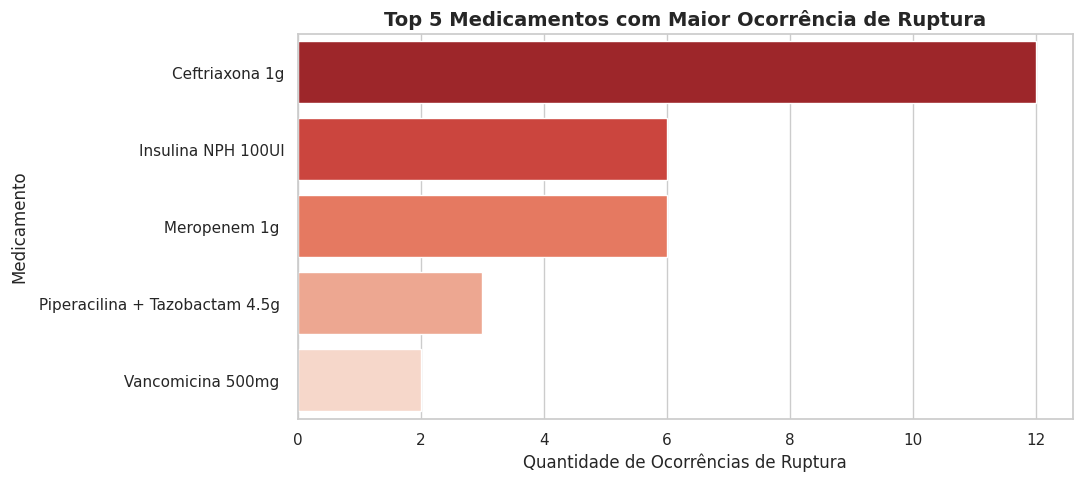

In [ ]:
# 1. Garantir que temos a tabela unificada (Solicitações + Medicamentos)
df_completo = pd.merge(
    df_solicitacoes,
    df_medicamentos,
    on="IDMedicamento",
    how="inner"
)

# 2. Filtrar apenas as solicitações com status 'RUPTURA'
df_rupturas = df_completo[df_completo['StatusSolicitacao'] == 'RUPTURA']

# 3. Contar e pegar os Top 5 medicamentos com mais rupturas
top_rupturas = df_rupturas['NomeMedicamento'].value_counts().head(5).reset_index()
top_rupturas.columns = ['NomeMedicamento', 'TotalRupturas']

# 4. Criar o gráfico de barras com Seaborn
plt.figure(figsize=(10, 5))
grafico = sns.barplot(
    data=top_rupturas,
    x='TotalRupturas',
    y='NomeMedicamento',
    palette='Reds_r'  # Tom avermelhado para destacar alerta/falta
)

# 5. Personalizar títulos e rótulos
plt.title('Top 5 Medicamentos com Maior Ocorrência de Ruptura', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de Ocorrências de Ruptura', fontsize=12)
plt.ylabel('Medicamento', fontsize=12)

# Exibir o gráfico no Colab
plt.show()

In [ ]:
from google.colab import files

# 1. Cruzar solicitações com medicamentos para ter a base completa
df_final = pd.merge(
    df_solicitacoes,
    df_medicamentos,
    on="IDMedicamento",
    how="left"
)

# 2. Exportar em UTF-8 com suporte a acentos para o Excel/Power BI
df_final.to_csv('farmacia_hospitalar_powerbi.csv', index=False, encoding='utf-8-sig')

# 3. Fazer o download automático do arquivo para o seu computador
files.download('farmacia_hospitalar_powerbi.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>